In [215]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

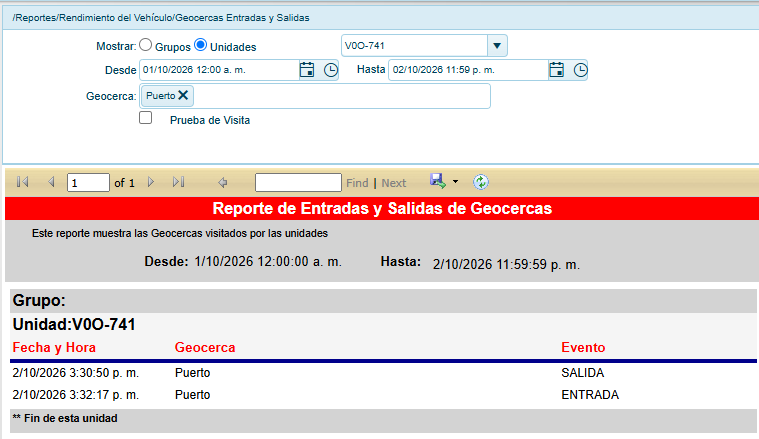
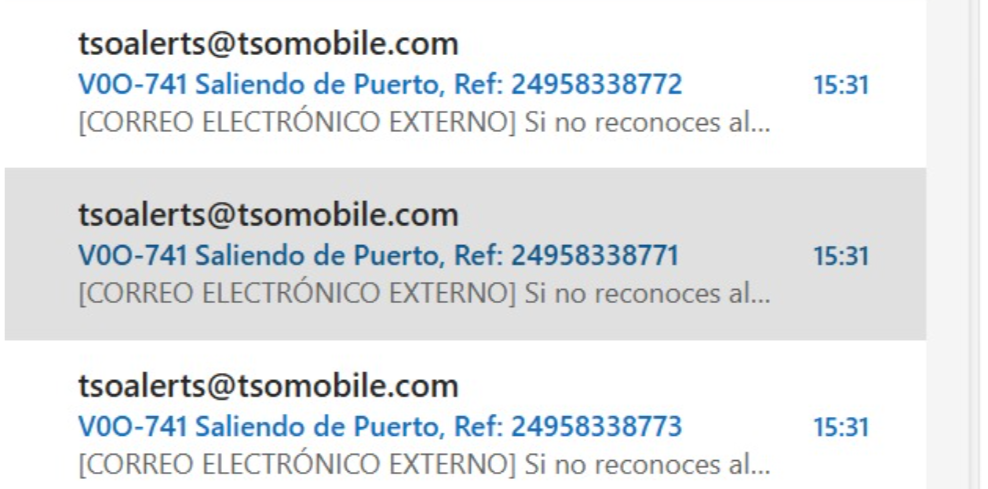
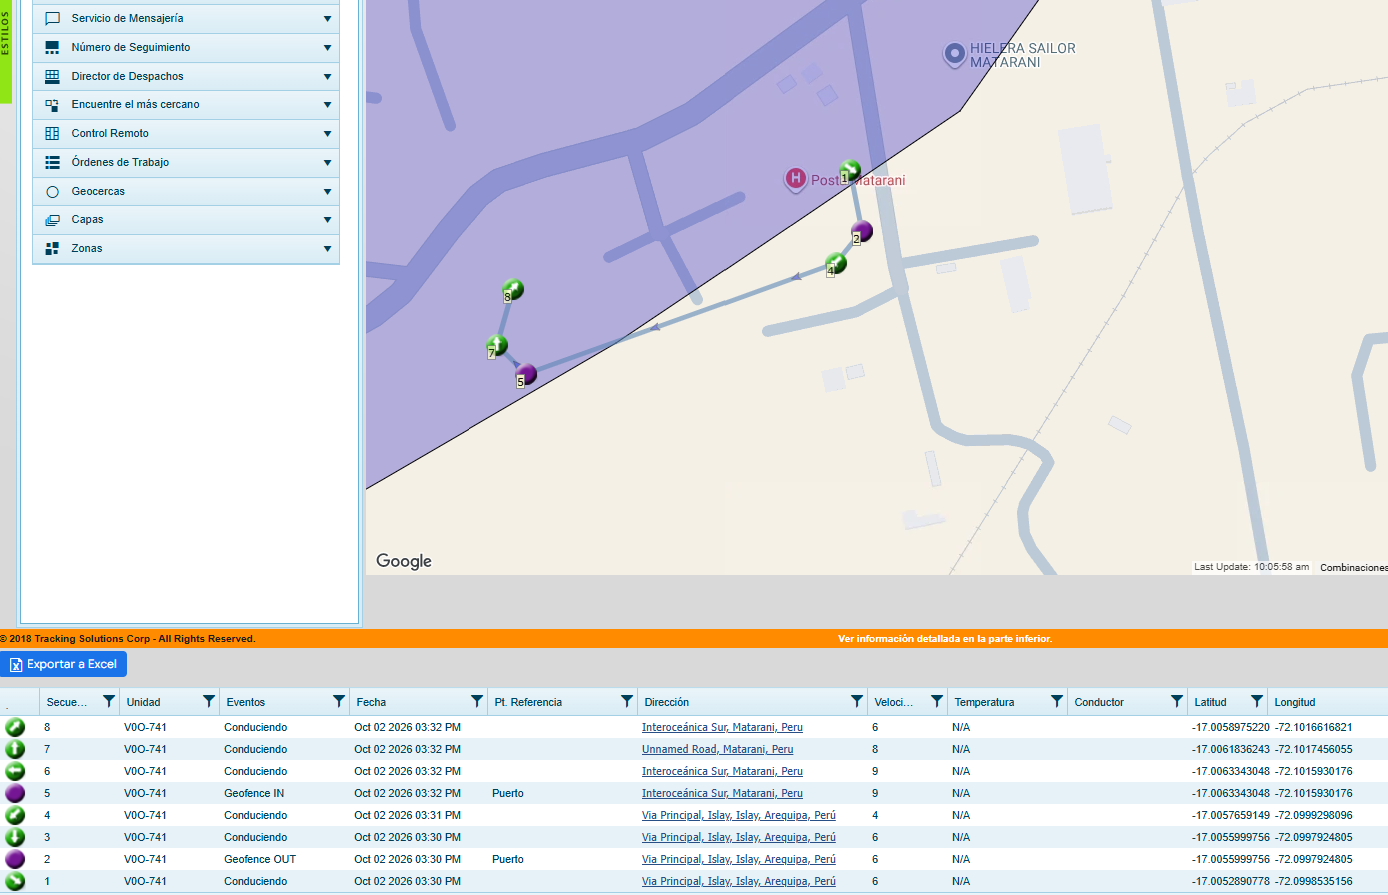

In [216]:
ar_geo=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\tisur\Reporte_Geocercas_20261104_1709.xlsx')
ar_geo.fillna('Nan',inplace=True)
ar_geo.rename(columns={'Geocerca':'Nombre','Unnamed: 3':'Latitud','Unnamed: 4':'Longitud'},inplace=True)

In [217]:
geo_name=ar_geo.iloc[0,0]
for i in range(0,ar_geo.shape[0]):    
    if ar_geo.iloc[i,0]=='Nan':
        ar_geo.iloc[i,0]=geo_name
    if ar_geo.iloc[i,0]!='Nan' and ar_geo.iloc[i,0]!=geo_name:
        geo_name=ar_geo.iloc[i,0]
        ar_geo.iloc[i,0]=geo_name

In [218]:
ar_lm=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\tisur\Puntos de Referencia.xlsx')
ar_lm_s1=ar_lm[['Nombre','Latitud','Longitud']]
ar_geo_s1=ar_geo[['Nombre','Latitud','Longitud']]
ar_t=pd.concat([ar_lm_s1,ar_geo_s1],axis=0)
ar_t.info()
ar_t.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\tisur\ar_t.csv',index=False)

<class 'pandas.DataFrame'>
Index: 1279 entries, 0 to 1262
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Nombre    1279 non-null   str    
 1   Latitud   1279 non-null   float64
 2   Longitud  1279 non-null   float64
dtypes: float64(2), str(1)
memory usage: 40.0 KB


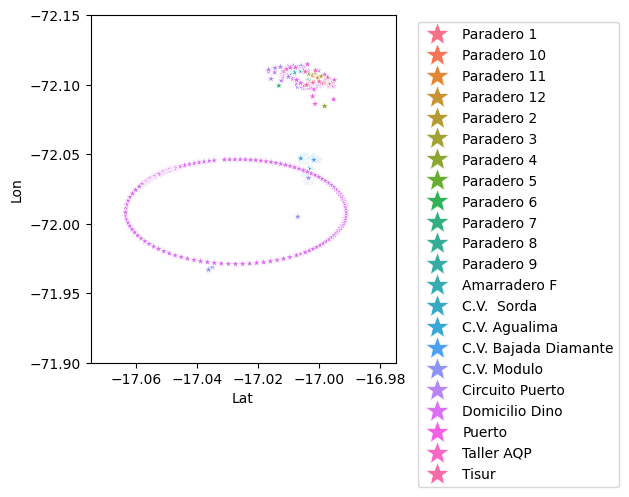

In [219]:
x_axis=[]
y_axis=[]
zone=[]
df=pd.DataFrame()

for i in range(0,ar_t.shape[0]):
    #try:
    x_axis.append(ar_t.iloc[i,1])
    y_axis.append(ar_t.iloc[i,2])
    zone.append(ar_t.iloc[i,0])
    #except:
    #print(ar_total.iloc[i,6], ' -> ',ar_total.iloc[i,7])

df['Zone']=zone
df['Lat']=x_axis
df['Lon']=y_axis

sns.scatterplot(data=df, x='Lat', marker='*',y='Lon', hue='Zone')

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left",markerscale=3)
plt.tight_layout()
plt.xlim(-17.075,-16.975)
plt.ylim(-71.9,-72.15)
plt.show()
